# Learning curve theo nhóm

Đo AP trên validation khi tăng lượng dữ liệu fit cho Random Forest cố định của tuần 3. Dùng 5 fold phân tầng theo nhóm của [phân tích bổ sung](04_robustness.ipynb). Các phiên có cùng 16 feature luôn thuộc cùng nhóm. Tập test nằm ngoài thí nghiệm này.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "project_model.py").is_file():
    project_root = project_root.parent
if not (project_root / "project_model.py").is_file():
    raise FileNotFoundError("Hãy chạy notebook từ thư mục gốc, notebooks/ hoặc submission/.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score
from sklearn.model_selection import StratifiedGroupKFold

from project_model import load_train, make_forest

X, y = load_train()
groups = X.groupby(list(X.columns), sort=False, dropna=False).ngroup()
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
fractions = [0.25, 0.50, 0.75, 1.00]

Trong mỗi fold, trộn các nhóm của phần fit bằng seed cố định. Lấy lần lượt 25%, 50%, 75% và 100% số nhóm từ đầu danh sách đã trộn. Các tập nhỏ nằm trong tập lớn hơn và giữ trọn nhóm. Số phiên thực tế có thể lệch nhẹ so với tỷ lệ nhóm. Giữ nguyên toàn bộ phần validation của fold ở mỗi mốc và fit lại cả pipeline từ đầu.

In [2]:
rows = []
for fold, (fit, val) in enumerate(cv.split(X, y, groups), start=1):
    fit_groups = groups.iloc[fit]
    assert not fit_groups.isin(groups.iloc[val]).any()
    rng = np.random.default_rng(42 + fold)
    ordered_groups = rng.permutation(fit_groups.unique())

    for fraction in fractions:
        n_groups = int(np.ceil(len(ordered_groups) * fraction))
        selected_groups = ordered_groups[:n_groups]
        rows_for_fit = fit[fit_groups.isin(selected_groups).to_numpy()]
        assert y.iloc[rows_for_fit].nunique() == 2

        model = make_forest(X.columns)
        model.fit(X.iloc[rows_for_fit], y.iloc[rows_for_fit])
        scores = model.predict_proba(X.iloc[val])[:, 1]
        rows.append({
            "Fold": fold,
            "Phần nhóm fit": fraction,
            "Số phiên fit": len(rows_for_fit),
            "Tỷ lệ mua trong phần fit": y.iloc[rows_for_fit].mean(),
            "AP validation": average_precision_score(y.iloc[val], scores),
        })

results = pd.DataFrame(rows)
summary = results.groupby("Phần nhóm fit").agg(
    mean_rows=("Số phiên fit", "mean"),
    mean_ap=("AP validation", "mean"),
    std_ap=("AP validation", lambda ap: ap.std(ddof=0)),
)
display(summary.round(5))
display(results.pivot(index="Fold", columns="Phần nhóm fit", values="AP validation").round(5))

,mean_rows,mean_ap,std_ap
Phần nhóm fit,,,
0.25,1972.6,0.35310,0.02233
0.50,3942.2,0.37836,0.02889
0.75,5917.0,0.37779,0.02338
1.00,7891.2,0.38277,0.02026


Phần nhóm fit,0.25,0.50,0.75,1.00
Fold,,,,
1,0.34299,0.36579,0.35304,0.37075
2,0.37383,0.38073,0.40384,0.39437
3,0.36939,0.40342,0.39074,0.39551
4,0.31382,0.33049,0.34645,0.34889
5,0.36548,0.41135,0.39486,0.40431


Các thanh sai số biểu thị độ lệch chuẩn AP giữa 5 fold. Chênh lệch trong notebook phản ánh các nhóm và kích cỡ đã thử trên UCI.

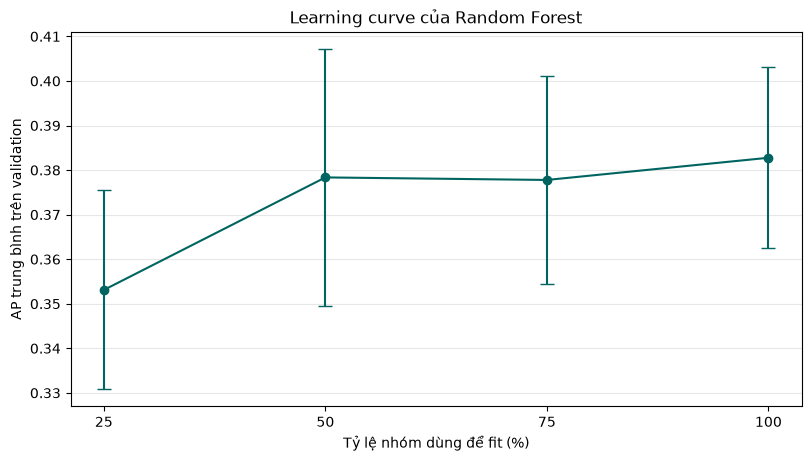

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ax.errorbar(summary.index * 100, summary["mean_ap"], yerr=summary["std_ap"],
            marker="o", capsize=5, color="#006560")
ax.set(xticks=[25, 50, 75, 100], xlabel="Tỷ lệ nhóm dùng để fit (%)",
       ylabel="AP trung bình trên validation", title="Learning curve của Random Forest")
ax.grid(axis="y", alpha=0.3)
plt.show()